In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4090


In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)

Using: cuda


In [3]:
import pandas as pd

train_df = pd.read_csv(
    r"E:\ADS2002_Melanoma\data\splits\train.csv"
)

val_df = pd.read_csv(
    r"E:\ADS2002_Melanoma\data\splits\validation.csv"
)

test_df = pd.read_csv(
    r"E:\ADS2002_Melanoma\data\splits\test.csv"
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 23098
Validation: 4657
Test: 4946


In [4]:
import os

image_folder = r"E:\ADS2002_Melanoma\data\raw\train"

example_name = train_df["image_name"].iloc[0]

example_path = os.path.join(
    image_folder,
    example_name + ".jpg"
)

print("Image name:", example_name)
print("Full path:", example_path)
print("Does it exist?", os.path.exists(example_path))

Image name: ISIC_2637011
Full path: E:\ADS2002_Melanoma\data\raw\train\ISIC_2637011.jpg
Does it exist? True


In [8]:
missing_train = 0

for image_name in train_df["image_name"]:

    image_path = os.path.join(
        image_folder,
        image_name + ".jpg"
    )

    if not os.path.exists(image_path):
        missing_train += 1

print("Missing training images:", missing_train)

missing_val = 0

for image_name in val_df["image_name"]:

    image_path = os.path.join(
        image_folder,
        image_name + ".jpg"
    )

    if not os.path.exists(image_path):
        missing_val += 1

print("Missing validation images:", missing_val)

missing_test = 0

for image_name in test_df["image_name"]:

    image_path = os.path.join(
        image_folder,
        image_name + ".jpg"
    )

    if not os.path.exists(image_path):
        missing_test += 1

print("Missing test images:", missing_test)

Missing training images: 0
Missing validation images: 0
Missing test images: 0


In [9]:
malignant_rows = train_df[
    train_df["target"] == 1
]

print("Malignant training images:", len(malignant_rows))

Malignant training images: 396


In [10]:
malignant_example = malignant_rows.iloc[0]

image_name = malignant_example["image_name"]

image_path = os.path.join(
    image_folder,
    image_name + ".jpg"
)

print(image_path)

E:\ADS2002_Melanoma\data\raw\train\ISIC_0207268.jpg


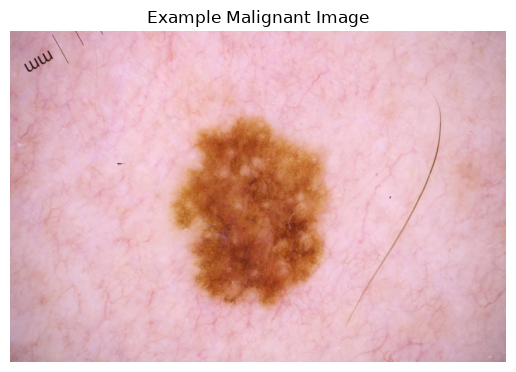

Image size: (6000, 4000)


In [12]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open(image_path)

plt.imshow(image)
plt.title("Example Malignant Image")
plt.axis("off")
plt.show()

print("Image size:", image.size)

In [ ]:
from torchvision import transforms